# InsightFuel Analytics — 04. Visualização e Análise Exploratória

Este notebook consome somente a camada **Gold** e produz gráficos para validar e explorar os resultados do projeto.

## 1. Configuração e conexão

In [19]:
from pathlib import Path
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

def find_project_root(start=Path.cwd()):
    start=Path(start).resolve()
    for p in [start]+list(start.parents):
        if (p / "data" / "bronze").exists(): return p
    raise FileNotFoundError("Pasta data/bronze não encontrada.")

PROJECT_ROOT=find_project_root()
DB_PATH=PROJECT_ROOT / "database" / "insightfuel.duckdb"
if not DB_PATH.exists():
    raise FileNotFoundError("DuckDB não encontrado. Execute 01_ingestao, 02_silver e 03_gold.")
con=duckdb.connect(str(DB_PATH))
print("Projeto:", PROJECT_ROOT)
print("Banco:", DB_PATH)

Projeto: C:\Users\Bruna\anaconda_projects\Trabalho_Armazenamento
Banco: C:\Users\Bruna\anaconda_projects\Trabalho_Armazenamento\database\insightfuel.duckdb


## 2. Verificar e carregar a Gold

In [20]:
gold_tables=con.execute("""SELECT table_name FROM information_schema.tables WHERE table_schema='gold' ORDER BY table_name""").df()
display(gold_tables)
required={"fato_preco_mensal","visao_municipio","visao_regional"}
missing=required-set(gold_tables["table_name"])
if missing: raise ValueError(f"Tabelas Gold ausentes: {missing}")
fato=con.execute("SELECT * FROM gold.fato_preco_mensal").df()
municipio=con.execute("SELECT * FROM gold.visao_municipio").df()
regional=con.execute("SELECT * FROM gold.visao_regional").df()
print("fato:",fato.shape,"municipio:",municipio.shape,"regional:",regional.shape)

,table_name
0,fato_preco_mensal
1,visao_municipio
2,visao_regional


fato: (72412, 11) municipio: (72412, 16) regional: (5494, 11)


## 3. Inspeção inicial

In [21]:
print("Colunas fato:", list(fato.columns))
print("Colunas municipio:", list(municipio.columns))
print("Colunas regional:", list(regional.columns))
display(fato.head())

Colunas fato: ['mes', 'uf', 'municipio', 'produto', 'preco_medio', 'preco_minimo', 'preco_maximo', 'desvio_padrao', 'quantidade_observacoes', 'ano', 'mes_numero']
Colunas municipio: ['mes', 'uf', 'municipio', 'produto', 'preco_medio', 'preco_minimo', 'preco_maximo', 'desvio_padrao', 'quantidade_observacoes', 'ano', 'mes_numero', 'chave_municipio', 'codigo_ibge', 'populacao', 'pib', 'pib_per_capita']
Colunas regional: ['mes', 'ano', 'mes_numero', 'uf', 'produto', 'preco_medio', 'preco_minimo', 'preco_maximo', 'desvio_padrao', 'quantidade_municipios', 'quantidade_observacoes']


,mes,uf,municipio,produto,preco_medio,preco_minimo,preco_maximo,desvio_padrao,quantidade_observacoes,ano,mes_numero
0,2021-01-01,AC,CRUZEIRO DO SUL,DIESEL,5.240000,5.23,5.25,0.010000,7,2021,1
1,2021-01-01,AC,CRUZEIRO DO SUL,DIESEL S10,5.260000,5.23,5.30,0.029439,10,2021,1
2,2021-01-01,AC,CRUZEIRO DO SUL,GASOLINA,5.939000,5.92,5.95,0.011972,10,2021,1
3,2021-01-01,AC,CRUZEIRO DO SUL,GASOLINA ADITIVADA,5.935000,5.93,5.95,0.010000,4,2021,1
4,2021-01-01,AC,RIO BRANCO,DIESEL,4.548093,4.30,4.80,0.104752,86,2021,1


## 4. Selecionar produto para análise

In [22]:
produtos=sorted(fato["produto"].dropna().astype(str).unique())
print("Produtos disponíveis:")
for i,p in enumerate(produtos,1): print(f"{i}. {p}")
if not produtos: raise ValueError("Nenhum produto encontrado.")
produto_analise=produtos[0]
print("Produto selecionado:",produto_analise)

Produtos disponíveis:
1. DIESEL
2. DIESEL S10
3. ETANOL
4. GASOLINA
5. GASOLINA ADITIVADA
6. GNV
Produto selecionado: DIESEL


## 5. Evolução mensal do preço

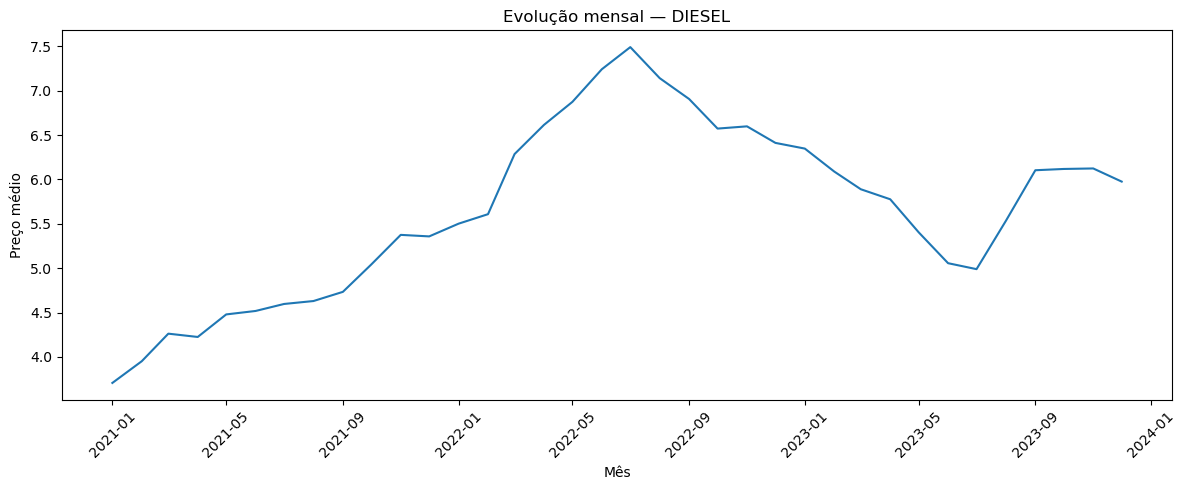

In [23]:
serie=(fato[fato["produto"].astype(str)==produto_analise].groupby("mes",as_index=False)["preco_medio"].mean().sort_values("mes"))
plt.figure(figsize=(12,5)); plt.plot(serie["mes"],serie["preco_medio"]); plt.title(f"Evolução mensal — {produto_analise}"); plt.xlabel("Mês"); plt.ylabel("Preço médio"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 6. Preço médio por UF

,uf,preco_medio
0,AC,6.766433
2,AM,6.120860
13,PA,6.084748
21,RR,6.076297
20,RO,6.042879
1,AL,5.917893
12,MT,5.917562
5,CE,5.886991
19,RN,5.868341
16,PI,5.842282


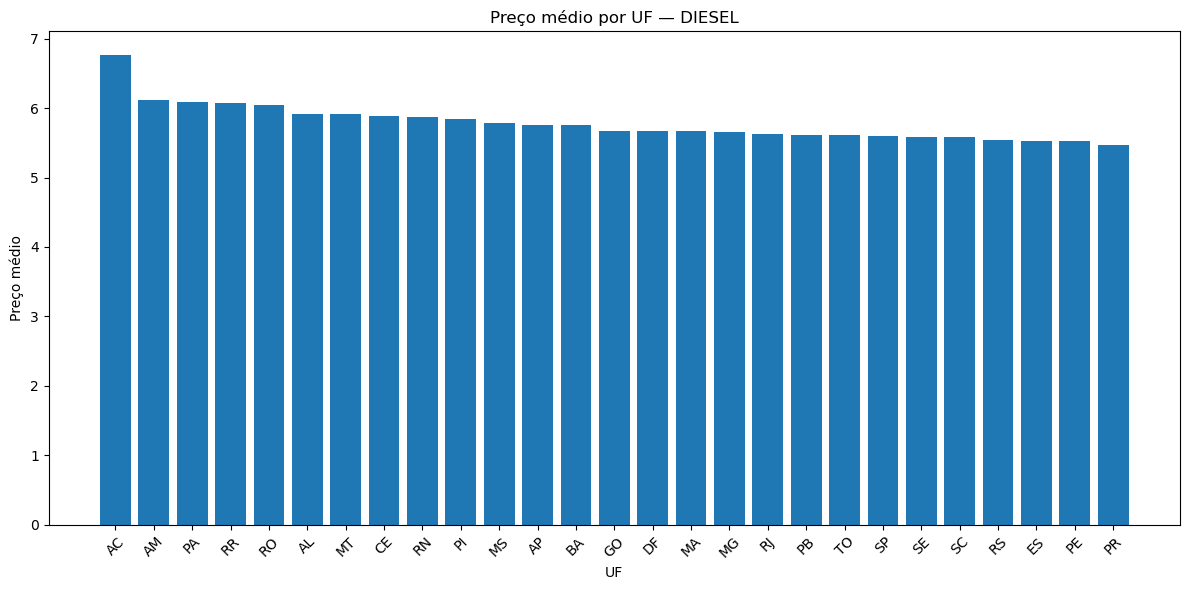

In [24]:
ranking_uf=(regional[regional["produto"].astype(str)==produto_analise].groupby("uf",as_index=False)["preco_medio"].mean().sort_values("preco_medio",ascending=False))
display(ranking_uf)
plt.figure(figsize=(12,6)); plt.bar(ranking_uf["uf"],ranking_uf["preco_medio"]); plt.title(f"Preço médio por UF — {produto_analise}"); plt.xlabel("UF"); plt.ylabel("Preço médio"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 7. Evolução por UF

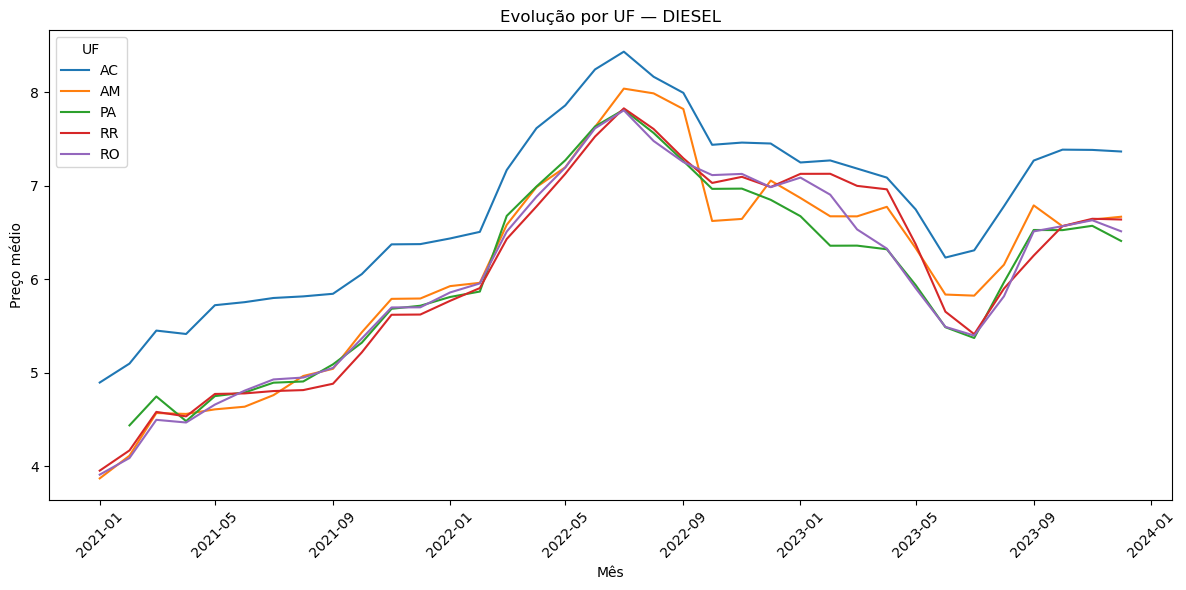

In [25]:
top_ufs=ranking_uf.head(min(5,len(ranking_uf)))["uf"].tolist()
dados=regional[(regional["produto"].astype(str)==produto_analise)&(regional["uf"].isin(top_ufs))].sort_values("mes")
plt.figure(figsize=(12,6))
for uf in top_ufs:
    d=dados[dados["uf"]==uf]; plt.plot(d["mes"],d["preco_medio"],label=uf)
plt.title(f"Evolução por UF — {produto_analise}"); plt.xlabel("Mês"); plt.ylabel("Preço médio"); plt.legend(title="UF"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 8. Distribuição dos preços municipais

,uf,municipio,preco_medio,populacao,pib,pib_per_capita
0,AC,CRUZEIRO DO SUL,7.041306,91888,2.343838e+06,25706.727188
1,AC,RIO BRANCO,6.451859,364756,1.172785e+07,30847.046667
2,AL,ARAPIRACA,5.840938,234696,6.229265e+06,26556.121429
3,AL,DELMIRO GOUVEIA,6.614378,51318,8.109159e+05,15727.708214
4,AL,MACEIO,5.751268,957916,3.020558e+07,30849.473333


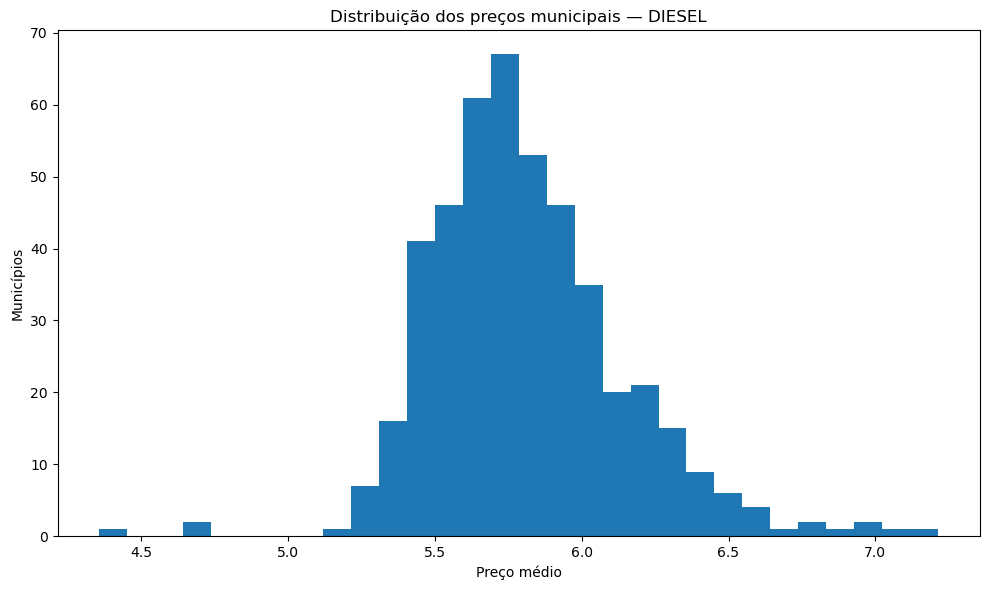

In [26]:
mp = municipio[
    municipio["produto"].astype(str) == produto_analise
].copy()

agg_dict = {
    "preco_medio": ("preco_medio", "mean"),
    "populacao": ("populacao", "first"),
}

if "pib" in mp.columns:
    agg_dict["pib"] = ("pib", "mean")

if "pib_per_capita" in mp.columns:
    agg_dict["pib_per_capita"] = ("pib_per_capita", "mean")

media_municipio = (
    mp.groupby(["uf", "municipio"], as_index=False)
    .agg(**agg_dict)
)

display(media_municipio.head())

plt.figure(figsize=(10, 6))
plt.hist(
    media_municipio["preco_medio"].dropna(),
    bins=30
)
plt.title(f"Distribuição dos preços municipais — {produto_analise}")
plt.xlabel("Preço médio")
plt.ylabel("Municípios")
plt.tight_layout()
plt.show()


## 9. Preço × população

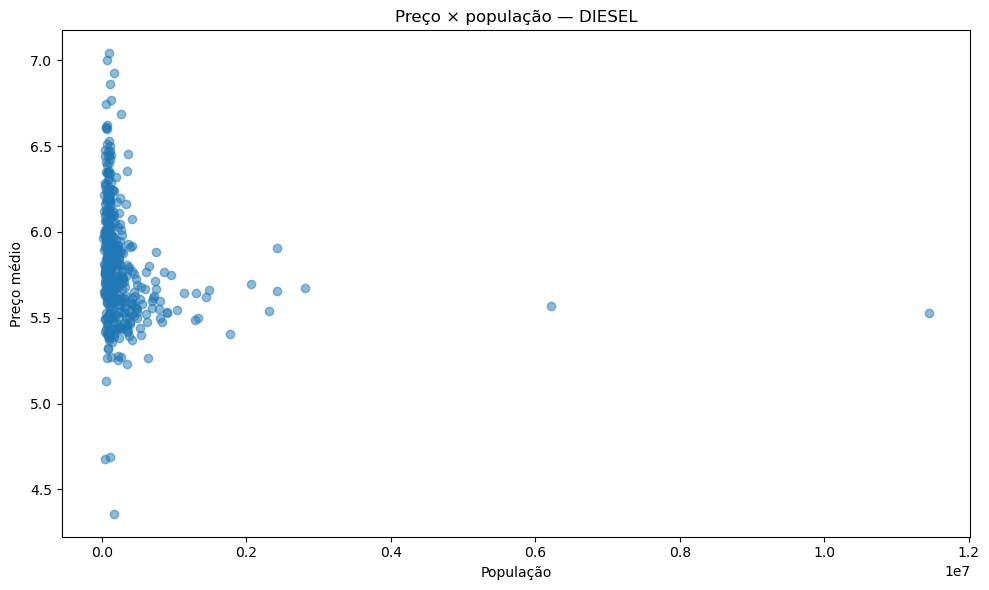

Correlação de Pearson: -0.15017240515767444


In [27]:
d=media_municipio.dropna(subset=["preco_medio","populacao"]).copy(); d=d[d["populacao"]>0]
if len(d):
    plt.figure(figsize=(10,6)); plt.scatter(d["populacao"],d["preco_medio"],alpha=.5); plt.title(f"Preço × população — {produto_analise}"); plt.xlabel("População"); plt.ylabel("Preço médio"); plt.tight_layout(); plt.show(); print("Correlação de Pearson:",d["populacao"].corr(d["preco_medio"]))
else: print("Sem dados suficientes de população.")

## 10. Preço × PIB per capita

Municípios com PIB per capita válido: 458


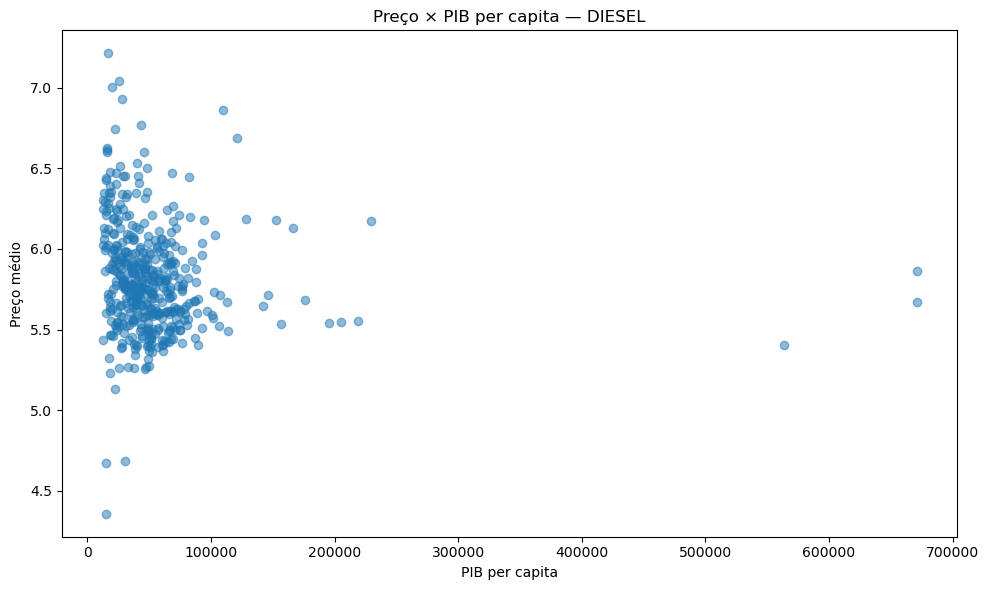

Correlação de Pearson: -0.09768384138006528


In [28]:
if "pib_per_capita" not in media_municipio.columns:
    print("PIB per capita não está disponível na Gold.")
else:
    d = media_municipio.dropna(
        subset=["preco_medio", "pib_per_capita"]
    ).copy()
    d = d[d["pib_per_capita"] > 0]

    print(f"Municípios com PIB per capita válido: {len(d):,}")

    if len(d):
        plt.figure(figsize=(10, 6))
        plt.scatter(
            d["pib_per_capita"],
            d["preco_medio"],
            alpha=.5
        )
        plt.title(
            f"Preço × PIB per capita — {produto_analise}"
        )
        plt.xlabel("PIB per capita")
        plt.ylabel("Preço médio")
        plt.tight_layout()
        plt.show()

        print(
            "Correlação de Pearson:",
            d["pib_per_capita"].corr(d["preco_medio"])
        )
    else:
        print("Sem dados válidos de PIB per capita para esta análise.")


## 11. Volatilidade por UF

,uf,desvio_padrao
2,AM,0.453163
0,AC,0.444876
13,PA,0.337155
1,AL,0.272969
11,MS,0.272925
15,PE,0.248530
22,RS,0.225329
12,MT,0.222296
4,BA,0.189767
9,MA,0.182842


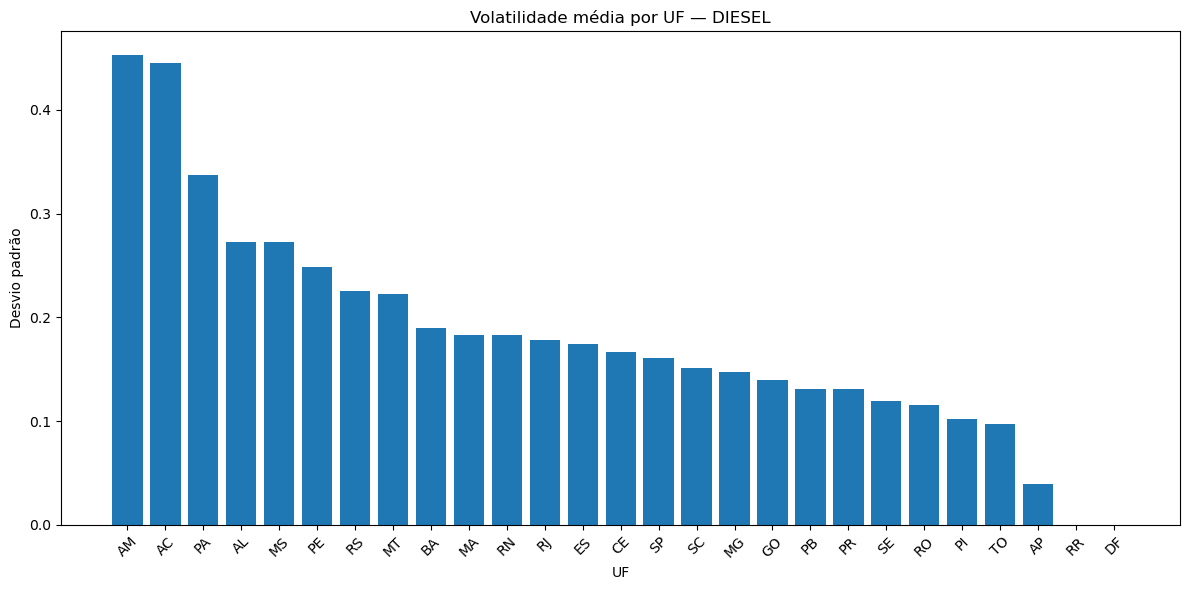

In [29]:
vol=(regional[regional["produto"].astype(str)==produto_analise].groupby("uf",as_index=False)["desvio_padrao"].mean().sort_values("desvio_padrao",ascending=False))
display(vol)
plt.figure(figsize=(12,6)); plt.bar(vol["uf"],vol["desvio_padrao"]); plt.title(f"Volatilidade média por UF — {produto_analise}"); plt.xlabel("UF"); plt.ylabel("Desvio padrão"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 12. Comparação entre produtos

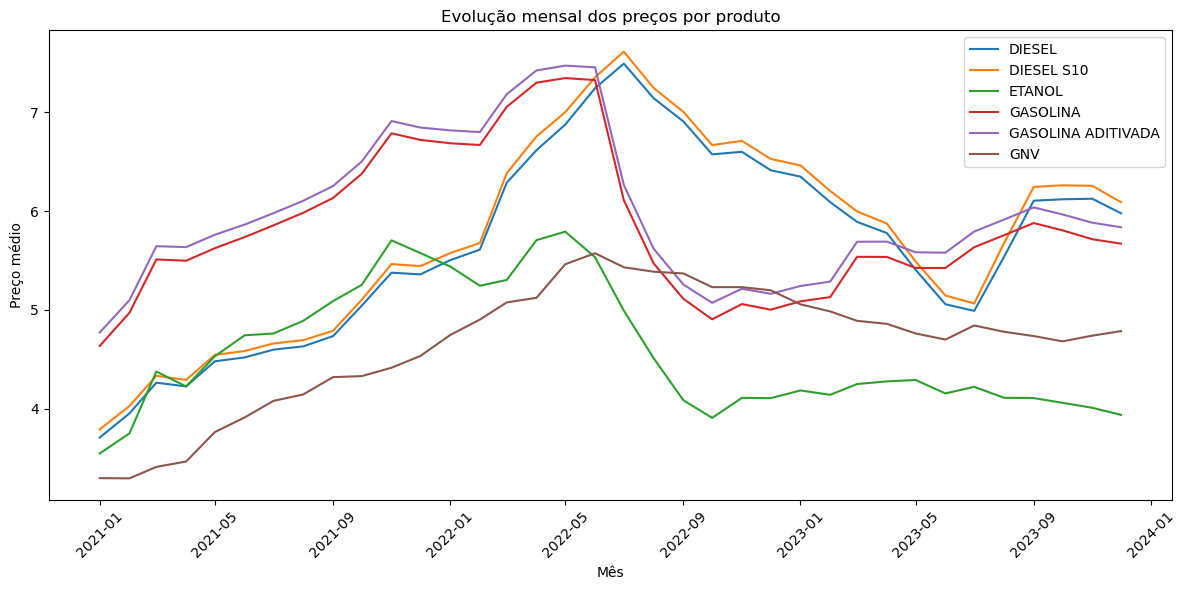

In [30]:
sp=fato.groupby(["mes","produto"],as_index=False)["preco_medio"].mean()
plt.figure(figsize=(12,6))
for p in sorted(sp["produto"].dropna().astype(str).unique()):
    d=sp[sp["produto"].astype(str)==p]; plt.plot(d["mes"],d["preco_medio"],label=p)
plt.title("Evolução mensal dos preços por produto"); plt.xlabel("Mês"); plt.ylabel("Preço médio"); plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 13. Tabela-resumo

In [31]:
resumo=con.execute("""SELECT produto,COUNT(*) AS registros_mensais,COUNT(DISTINCT municipio) AS municipios,COUNT(DISTINCT uf) AS ufs,MIN(mes) AS primeira_referencia,MAX(mes) AS ultima_referencia,ROUND(AVG(preco_medio),3) AS preco_medio_periodo FROM gold.fato_preco_mensal GROUP BY produto ORDER BY produto""").df()
display(resumo)

,produto,registros_mensais,municipios,ufs,primeira_referencia,ultima_referencia,preco_medio_periodo
0,DIESEL,13093,458,27,2021-01-01,2023-12-01,5.779
1,DIESEL S10,13663,463,27,2021-01-01,2023-12-01,5.878
2,ETANOL,13526,459,27,2021-01-01,2023-12-01,4.626
3,GASOLINA,13728,464,27,2021-01-01,2023-12-01,5.926
4,GASOLINA ADITIVADA,13608,460,27,2021-01-01,2023-12-01,6.070
5,GNV,4794,211,22,2021-01-01,2023-12-01,4.700


## 14. Encerrar conexão

In [32]:
con.close()
print("Conexão com o DuckDB encerrada.")

Conexão com o DuckDB encerrada.
